<a href="https://colab.research.google.com/github/yonatantamiru65-tech/DEEP-REINFORCEMENT-LEARNING-BASED-LOCOMOTION-CONTROL-FOR-QUADRUPED-ROBOTS-/blob/main/2026_01_09_unicycle_example_lg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Optimal Control of a Unicycle with Pyomo


These notes were developed by Thomas Fork, Charlott Vallon, Roya Firoozi, Francesco Borrelli at UC Berkeley, and Luigi Glielmo at Università di Napoli Federico II. They are protected by U.S. copyright law and by University policy (https://copyright.universityofcalifornia.edu/resources/ownership-course-materials.html).

You may not reproduce, distribute or display (post/upload) lecture notes or recordings or course materials in any way — whether or not a fee is charged — without my express written consent. You also may not allow others to do so. If you do so, you may be subject to student conduct proceedings under the Berkeley Code of Student Conduct, including Sections 102.23 and 102.25.

## Loading Libraries

In [2]:
!pip install -q pyomo
!wget -N -O ipopt-linux64.zip https://drive.google.com/uc?id=1BBrEZanNTfQvdC1GoU9VRjsFPb1Nu3Ik&export=download
!unzip -o -q ipopt-linux64


for details.

--2026-01-09 14:42:50--  https://drive.google.com/uc?id=1BBrEZanNTfQvdC1GoU9VRjsFPb1Nu3Ik
Resolving drive.google.com (drive.google.com)... 142.251.179.138, 142.251.179.139, 142.251.179.101, ...
Connecting to drive.google.com (drive.google.com)|142.251.179.138|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1BBrEZanNTfQvdC1GoU9VRjsFPb1Nu3Ik [following]
--2026-01-09 14:42:50--  https://drive.usercontent.google.com/download?id=1BBrEZanNTfQvdC1GoU9VRjsFPb1Nu3Ik
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 142.250.31.132, 2607:f8b0:4004:c0b::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|142.250.31.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1817178 (1.7M) [application/octet-stream]
Saving to: ‘ipopt-linux64.zip’

ipopt-linux64.zip   100%[===================>]   1.73M  --.-KB/s    in 0.08s   

2026-01-09

# Problem Statement


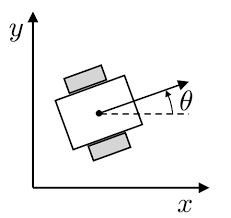






Consider a simple three-state model of a unicycle:
\begin{align}
 {\dot x} &= \cos(\theta) \, v\\
{\dot y} &= \sin(\theta) \, v\\
{\dot {\theta}} &=  \omega
\end{align}
where the control inputs are $u=[v,\omega]$ and the state is the unicycle pose
$z=[x,y,\theta]$.
The control objective is to bring the unicycle from an initial pose to a given termimal pose $\bar{z}_f$ at time $T$  under some input constraints:
\begin{align}
\mid v \mid &\leq 1 \ \rm{m/s}\\
\mid \omega \mid &\leq  1 ~\rm{rad/s}
\end{align}
We can also add input rate constraints like
\begin{align}
\mid \dot{v} \mid &\leq 0.3 ~\rm{m/s^2}\\
\mid \dot{\omega} \mid &\leq 0.3~\rm{rad/s^2}
\end{align}


# Euler Discretization
Assume the sampling time is $T_s$. With Euler discretization, the model becomes
\begin{equation}
z(t+1) = z(t) +T_s \, f(z(t),u(t))
\end{equation}
where
\begin{align}
f_1(z,u) &=  \cos(z_3) \, u_1\\
f_2(z,u) &=  \sin(z_3)\, u_1\\
f_3(z,u) &=  u_2\\
\end{align}


In [3]:
# x is state vector, u is input, Ts is sampling period, gamma and tau are parameters
def fdis(x, u, Ts):
    z_next = np.empty((3,))
    z_next[0] = x[0] + Ts * (np.cos(x[2]) * u[0])  # Use x instead of z
    z_next[1] = x[1] + Ts * (np.sin(x[2]) * u[0])  # Use x instead of z
    z_next[2] = x[2] + Ts * u[1]                    # Use x instead of z
    return z_next

# Finite Constrained Optimization Problem
We would like to solve the following FTCOC problem
\begin{align}
\min_{z_0,\ldots,z_T,u_0,\ldots,u_{T-1}} & \sum_{k=0}^{T-1} \|v_k \|_2^2 \nonumber\\
& z_{k+1} = z_k + T_s \, f(z_k,u_k) &&~\forall k = \left\{0,\ldots,T-1 \right\} \nonumber\\
& z_{\min} \leq z_k \leq z_{\max} &&~\forall k = \left\{0,\ldots,T \right\} \nonumber\\
& u_{\min} \leq u_k \leq u_{\max} &&~\forall k = \left\{0,\ldots,T-1 \right\} \nonumber\\
& z_0 = \bar{z}_0\nonumber\nonumber\\
& z_T = \bar{z}_f\nonumber
\end{align}

Now we formulate the CFTOC problem with Pyomo

In [4]:
# Finite constrained optimization problem
import pyomo.environ as pyo
import numpy as np

# simulation parameters
Ts = 0.05
T = 150
TFinal = Ts*T
nz = 3           # number of states
nu = 2           # number of inputs
z0=[0, 0, np.pi/4]       # initial condition
zf=[2, 1, np.pi] # terminal condition

# Flag to enable/disable input rate constraints
use_rate_constraints = False  # Set to False to disable
u_rate_max = [0.1, 0.1]  # Maximum rate for speed and steering


# Input constraints with generic bounds (as vectors)
u_min = [0, -1]  # Set your desired minimum bounds for [u_0, u_1]
u_max = [2, 1]    # Set your desired maximum bounds for [u_0, u_1]


model = pyo.ConcreteModel()
model.tidx = pyo.Set(initialize=range(0, T+1)) # length of finite optimization problem
model.zidx = pyo.Set(initialize=range(0, nz))  # number of states
model.uidx = pyo.Set(initialize=range(0, nu))  # number of inputs

# Create state and input variables trajectory:
model.z = pyo.Var(model.zidx, model.tidx)
model.u = pyo.Var(model.uidx, model.tidx)

# Constraints:
# initial condition
model.constraint1 = pyo.Constraint(model.zidx, rule=lambda model, i: model.z[i, 0] == z0[i])
# dynamics
model.constraint2 = pyo.Constraint(model.tidx, rule=lambda model, t: model.z[0, t+1] == model.z[0, t] + Ts* (pyo.cos(model.z[2, t]) *model.u[0, t])
                                   if t < T else pyo.Constraint.Skip)
model.constraint3 = pyo.Constraint(model.tidx, rule=lambda model, t: model.z[1, t+1] == model.z[1, t] + Ts* (pyo.sin(model.z[2, t]) *model.u[0, t])
                                   if t < T else pyo.Constraint.Skip)
model.constraint4 = pyo.Constraint(model.tidx, rule=lambda model, t: model.z[2, t+1] == model.z[2, t] + Ts* model.u[1, t]
                                   if t < T else pyo.Constraint.Skip)
# input constraints
model.constraint5 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[0, t] <= u_max[0]
                                   if t <= T-1 else pyo.Constraint.Skip)
model.constraint6 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[0, t] >= u_min[0]
                                   if t <= T-1 else pyo.Constraint.Skip)
model.constraint7 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[1, t] <= u_max[1]
                                   if t <= T-1 else pyo.Constraint.Skip)
model.constraint8 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[1, t] >= u_min[1]
                                   if t <= T-1 else pyo.Constraint.Skip)

if use_rate_constraints:
  # input rate constraints on speed
  model.constraint9 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[0, t+1] - model.u[0, t] <= u_rate_max[0]
                                   if t <= T-2 else pyo.Constraint.Skip)
  model.constraint10 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[0, t+1] - model.u[0, t] >= -u_rate_max[0]
                                   if t <= T-2 else pyo.Constraint.Skip)
  # input rate constraints on steering
  model.constraint13 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[1, t+1] - model.u[1, t] <= u_rate_max[1]
                                   if t <= T-2 else pyo.Constraint.Skip)
  model.constraint14 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[1, t+1] - model.u[1, t] >= -u_rate_max[1]
                                   if t <= T-2 else pyo.Constraint.Skip)

#model.constraint15 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[1, t] <= 0.3)
#model.constraint16 = pyo.Constraint(model.tidx, rule=lambda model, t: model.u[1, t] >= -0.3)
# terminal constraint
model.constraint17 = pyo.Constraint(model.zidx, rule=lambda model, i: model.z[i, T] == zf[i])


# Objective: (note we can formulate different objectives based on our desired control goal)
model.speed_cost = sum((model.u[0, t])**2 for t in model.tidx if t < T)
model.shortest_time_cost  = sum((model.z[0, t]-zf[0])**2+(model.z[1, t]-zf[1])**2 for t in model.tidx if t < T)
model.turning_cost = sum((model.u[1, t])**2 for t in model.tidx if t < T)
model.cost = pyo.Objective(expr = model.speed_cost, sense=pyo.minimize)

# Now we can solve:
results = pyo.SolverFactory('ipopt').solve(model).write()
# Note that Pyomo also outputs Solver Results, which indicate if the optimal control problem was feasible and if an optimal solution was found.

# ==========================================================
# = Solver Results                                         =
# ==========================================================
# ----------------------------------------------------------
#   Problem Information
# ----------------------------------------------------------
Problem: 
- Lower bound: -.inf
  Upper bound: .inf
  Number of objectives: 1
  Number of constraints: 1056
  Number of variables: 753
  Sense: unknown
# ----------------------------------------------------------
#   Solver Information
# ----------------------------------------------------------
Solver: 
- Status: ok
  Message: Ipopt 3.12.13\x3a Optimal Solution Found
  Termination condition: optimal
  Id: 0
  Error rc: 0
  Time: 0.39792823791503906
# ----------------------------------------------------------
#   Solution Information
# ----------------------------------------------------------
Solution: 
- number of solutions: 0
  number of solutions displayed: 0


# Plot and analyze the solution

<>:39: SyntaxWarning: invalid escape sequence '\o'
<>:39: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipython-input-4290923977.py:39: SyntaxWarning: invalid escape sequence '\o'
  plt.title('v (red) and $\omega$ (blue) vs. time trajectories')


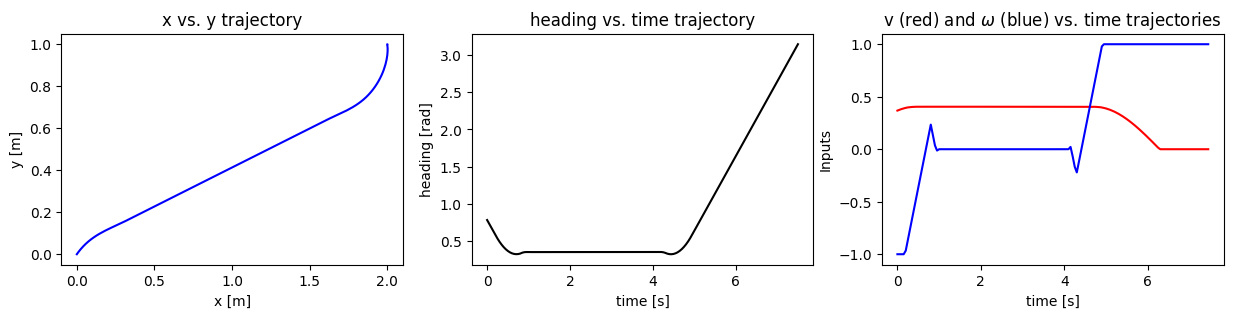

In [ ]:
import matplotlib.pyplot as plt

# Collect optimal solution
z1 = [pyo.value(model.z[0,0])]
z2 = [pyo.value(model.z[1,0])]
z3 = [pyo.value(model.z[2,0])]
u1 = [pyo.value(model.u[0,0])]
u2 = [pyo.value(model.u[1,0])]

#optimal value of the cost function
uopt_star = [pyo.value(model.cost)]

for t in model.tidx:
    if t < T:
        z1.append(pyo.value(model.z[0,t+1]))
        z2.append(pyo.value(model.z[1,t+1]))
        z3.append(pyo.value(model.z[2,t+1]))
    if t < T-1:
        u1.append(pyo.value(model.u[0,t+1]))
        u2.append(pyo.value(model.u[1,t+1]))

# Static plot of the results
plt.figure(figsize=[15,3])
plt.subplot(1, 3, 1)
plt.plot(z1, z2,'b')
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.title('x vs. y trajectory')
plt.subplot(1,3,2)
plt.plot(np.arange(T+1)*Ts, z3,'k')
plt.xlabel('time [s]')
plt.ylabel('heading [rad]')
plt.title('heading vs. time trajectory')
plt.subplot(1,3,3)
plt.plot(np.arange(T)*Ts, u1,'r')
plt.plot(np.arange(T)*Ts, u2,'b')
plt.xlabel('time [s]')
plt.ylabel('Inputs')
plt.title('v (red) and $\omega$ (blue) vs. time trajectories')
plt.show()


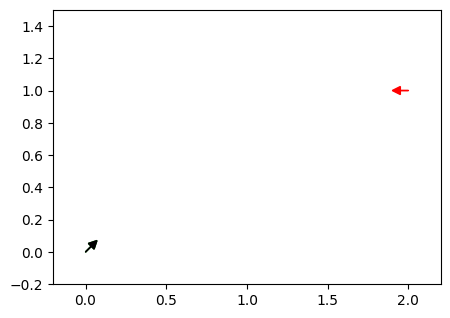

In [ ]:
# Animate the solution
from matplotlib import animation, rc
from IPython.display import HTML
import IPython.display

rc('animation', html='jshtml')

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, autoscale_on=False, xlim=(-1, 1), ylim=(-1.5, 1.5))
ax.set_aspect('equal')
ax.grid()

def animate(i):

    ax.cla()

    dxstart = Ts * np.cos(z3[0])
    dystart = Ts * np.sin(z3[0])
    ax.arrow(z1[0], z2[0], dxstart, dystart, head_width = 0.05, head_length = 0.05, fc = 'green', ec = 'green')

    dxend = Ts * np.cos(z3[-1])
    dyend = Ts * np.sin(z3[-1])
    ax.arrow(z1[-1], z2[-1], dxend, dyend, head_width = 0.05, head_length = 0.05, fc = 'red', ec = 'red')

    dx = Ts * np.cos(z3[i])
    dy = Ts * np.sin(z3[i])
    ax.arrow(z1[i], z2[i], dx, dy, head_width = 0.05, head_length = 0.05, fc = 'black', ec = 'black')

    ax.set(xlim = (-0.2, 2.2), ylim = (-0.2, 1.5))

ani = animation.FuncAnimation(fig, animate, interval=100, frames=len(z1), blit=False)


IPython.display.display(ani)


#Analysis:


1.   The cost function is used to encode the control objective. Several possible cost functions have been coded up above; how do the optimal trajectories differ for different costs? You can also try formulating other costs you think might be interesting. Does the resulting optimal trajectory look as expected?
2.   To explore the input of rate constraints, try changing the bounds. How does this affect the solution?



**Home Assignment**

Modify the unicycle model by assuming that the test model $f_{\rm test}$ differs from the prediction model $f$. Specifically, define $f_{\rm test}$ to include an input scaling factor of 0.9 on the linear velocity command $v(t)$. That is, in the test model, the actual applied velocity is $0.9 v(t)$,
while the prediction model assumes perfect actuation with input v(t).
Analyze how this model mismatch affects the behavior of system $f_{\rm test}${ when is controlled.



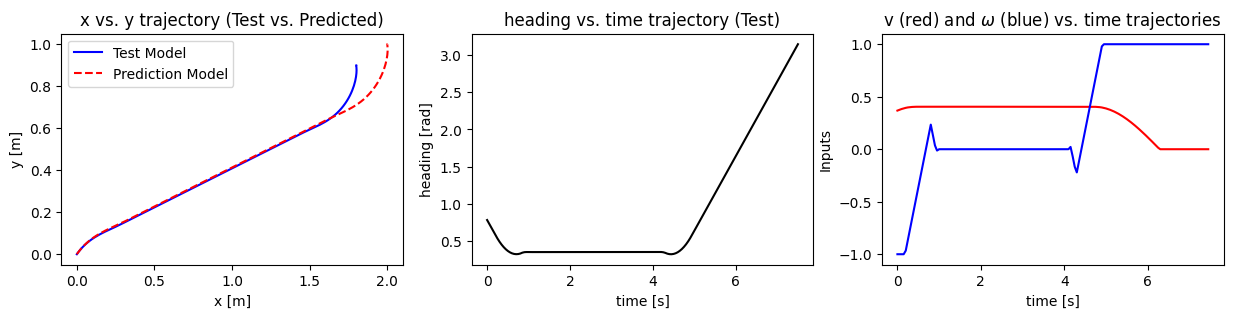

In [ ]:
# Test model with input scaling
def f_test(z, u):
    # Apply scaling factor to linear velocity input
    v = 0.9 * u[0]
    z_next    = np.empty((3,))
    z_next[0] = z[0] + Ts * (np.cos(z[2]) * v)
    z_next[1] = z[1] + Ts * (np.sin(z[2]) * v)
    z_next[2] = z[2] + Ts * u[1]
    return z_next

# Simulation using the test model and control sequence from the prediction model
z_test = [z0]  # Initialize state trajectory for the test model

for t in range(T):
    u_t = [u1[t],u2[t]]
    z_next_test = f_test(z_test[-1], u_t)
    z_test.append(z_next_test)

# Extract states for plotting
z1_test = [z[0] for z in z_test]
z2_test = [z[1] for z in z_test]
z3_test = [z[2] for z in z_test]

# Plotting the results of the test model
plt.figure(figsize=[15,3])
plt.subplot(1, 3, 1)
plt.plot(z1_test, z2_test,'b') #plot the test trajectory
plt.plot(z1, z2,'r--') #plot the predicted trajectory (for comparison)
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.title('x vs. y trajectory (Test vs. Predicted)')
plt.legend(['Test Model','Prediction Model'])
plt.subplot(1,3,2)
plt.plot(np.arange(T+1)*Ts, z3_test,'k')
plt.xlabel('time [s]')
plt.ylabel('heading [rad]')
plt.title('heading vs. time trajectory (Test)')
plt.subplot(1,3,3)
plt.plot(np.arange(T)*Ts, u1,'r')
plt.plot(np.arange(T)*Ts, u2,'b')
plt.xlabel('time [s]')
plt.ylabel('Inputs')
plt.title('v (red) and $\omega$ (blue) vs. time trajectories')
plt.show()


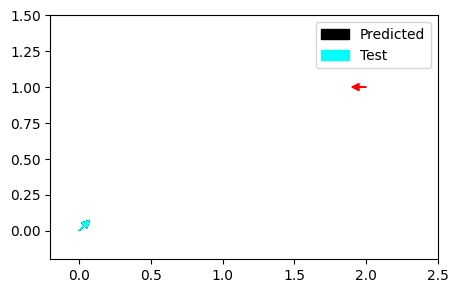

In [ ]:
# prompt: generate an animation showing the output for both the test and the predicted model, i.e. both z and z_test in the same animation

import matplotlib.pyplot as plt
from matplotlib import animation, rc
from IPython.display import HTML
import IPython.display

rc('animation', html='jshtml')

fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111, autoscale_on=False, xlim=(-1, 3), ylim=(-1, 2)) # Adjusted limits
ax.set_aspect('equal')
ax.grid()

def animate(i):
    l = 0.05
    ax.cla()

    dxstart =l*np.cos(z3[0])
    dystart = l*np.sin(z3[0])
    ax.arrow(z1[0], z2[0], dxstart, dystart, head_width = 0.05, head_length = 0.05, fc = 'green', ec = 'green')

    dxend =l*np.cos(z3[-1])
    dyend = l*np.sin(z3[-1])
    ax.arrow(z1[-1], z2[-1], dxend, dyend, head_width = 0.05, head_length = 0.05, fc = 'red', ec = 'red')

    # Predicted Model
    dx = l * np.cos(z3[i])
    dy = l * np.sin(z3[i])
    ax.arrow(z1[i], z2[i], dx, dy, head_width=0.05, head_length=0.05, fc='black', ec='black', label='Predicted')

    # Test Model
    dx_test = l * np.cos(z3_test[i])
    dy_test = l * np.sin(z3_test[i])
    ax.arrow(z1_test[i], z2_test[i], dx_test, dy_test, head_width=0.05, head_length=0.05, fc='cyan', ec='cyan', label='Test')

    ax.set(xlim=(-0.2, 2.5), ylim=(-0.2, 1.5)) # Adjusted limits
    ax.legend() # Added legend

ani = animation.FuncAnimation(fig, animate, interval=100, frames=min(len(z1), len(z1_test)), blit=False) # Use min length
IPython.display.display(ani)
